In [46]:
import os
import time
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

YOLOV9_DIR = "/home/f15c/H/yolov9"

YOLOV9_DATA = "/home/f15c/H/Plastic_Shampoo_Bottle_Dataset/data.yaml"

YOLOV9_WEIGHTS = "/home/f15c/H/yolov9/yolov9-c.pt"

YOLOV9_CFG = "/home/f15c/H/yolov9/models/detect/yolov9-c.yaml"

YOLOV9_RUN_NAME = "YOLOv9C_Plastic_Shampoo_Bottle7"
YOLOV9_PROJECT = "/home/f15c/H/runs/yolov9"

In [47]:
from pathlib import Path

files = [
    "/home/f15c/H/yolov9/train.py",
    "/home/f15c/H/yolov9/train_dual.py"
]

for file in files:

    path = Path(file)

    text = path.read_text(encoding="utf-8")

    text = text.replace(
        "torch.load(weights, map_location='cpu')",
        "torch.load(weights, map_location='cpu', weights_only=False)"
    )

    path.write_text(text, encoding="utf-8")

    print("Patched:", file)

Patched: /home/f15c/H/yolov9/train.py
Patched: /home/f15c/H/yolov9/train_dual.py


In [6]:
!grep -n "torch.load" /home/f15c/H/yolov9/train_dual.py

110:        ckpt = torch.load(weights, map_location="cpu", weights_only=False)
506:            d = torch.load(last, map_location='cpu')['opt']


In [1]:
from pathlib import Path
import re

text = Path("train_dual.py").read_text(
    encoding='utf-8',
    errors='ignore'
)

match = re.search(
    r"default='(\w+)'",
    text
)

print("Optimizer:", match.group(1))

Optimizer: SGD


In [1]:
!python /home/f15c/H/yolov9/train_dual.py --workers 2 --device 0  --batch 4 --epochs 50 --img 640 --data /home/f15c/H/Plastic_Shampoo_Bottle_Dataset/data.yaml --weights /home/f15c/H/yolov9/yolov9-c.pt --cfg /home/f15c/H/yolov9/models/detect/yolov9-c.yaml --hyp /home/f15c/H/yolov9/data/hyps/hyp.scratch-high.yaml --project /home/f15c/H/runs/yolov9 --name YOLOv9C_Plastic_Shampoo_Bottle

2026-06-21 19:33:26.842429: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
train_dual: weights=/home/f15c/H/yolov9/yolov9-c.pt, cfg=/home/f15c/H/yolov9/models/detect/yolov9-c.yaml, data=/home/f15c/H/Plastic_Shampoo_Bottle_Dataset/data.yaml, hyp=/home/f15c/H/yolov9/data/hyps/hyp.scratch-high.yaml, epochs=50, batch_size=4, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, bucket=, cache=None, image_weights=False, device=0, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=2, project=/home/f15c/H/runs/yolov9, name=YOLOv9C_Plastic_Shampoo_Bottle, exist_ok=False, quad=False, cos_lr=False, flat_cos_lr=False, fixed_lr=False, label_smoothing=0.0, patience=100, freeze=[0], sav

In [8]:
from pathlib import Path

loss_file = Path("loss_tal.py")

text = loss_file.read_text(
    encoding="utf-8",
    errors="ignore"
)

keywords = [
    "BCEWithLogitsLoss",
    "DFLoss",
    "bbox_iou",
    "VarifocalLoss",
    "FocalLoss",
    "BboxLoss",
    "ComputeLoss"
]

for i, line in enumerate(text.splitlines(), start=1):
    for k in keywords:
        if k in line:
            print(f"{i}: {line}")

8: from utils.metrics import bbox_iou
19: class VarifocalLoss(nn.Module):
32: class FocalLoss(nn.Module):
33:     # Wraps focal loss around existing loss_fcn(), i.e. criteria = FocalLoss(nn.BCEWithLogitsLoss(), gamma=1.5)
33:     # Wraps focal loss around existing loss_fcn(), i.e. criteria = FocalLoss(nn.BCEWithLogitsLoss(), gamma=1.5)
36:         self.loss_fcn = loss_fcn  # must be nn.BCEWithLogitsLoss()
62: class BboxLoss(nn.Module):
75:         iou = bbox_iou(pred_bboxes_pos, target_bboxes_pos, xywh=False, CIoU=True)
106: class ComputeLoss:
113:         BCEcls = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([h["cls_pw"]], device=device), reduction='none')
121:             BCEcls = FocalLoss(BCEcls, g)
138:         self.bbox_loss = BboxLoss(m.reg_max - 1, use_dfl=use_dfl).to(device)


In [10]:
print("Classification Loss : BCEWithLogitsLoss")
print("Box Loss            : CIoU Loss")
print("DFL Loss            : Distribution Focal Loss")

Classification Loss : BCEWithLogitsLoss
Box Loss            : CIoU Loss
DFL Loss            : Distribution Focal Loss


In [48]:
import os

YOLOV9_RESULTS_DIR = os.path.join(
    YOLOV9_PROJECT,
    YOLOV9_RUN_NAME
)

print(YOLOV9_RESULTS_DIR)

/home/f15c/H/runs/yolov9/YOLOv9C_Plastic_Shampoo_Bottle7


In [49]:
import os

for file in os.listdir(YOLOV9_RESULTS_DIR):
    print(file)

events.out.tfevents.1782063208.ki-028.298970.0
hyp.yaml
labels_correlogram.jpg
labels.jpg
opt.yaml
results.csv
weights


In [50]:
results_csv = os.path.join(
    YOLOV9_RESULTS_DIR,
    "results.csv"
)

yolov9_results = pd.read_csv(results_csv)

print(yolov9_results.head())

                  epoch        train/box_loss        train/cls_loss  \
0                     0                3.0157                3.7925   
1                     1                2.7011                2.3679   
2                     2                2.7450                2.3054   
3                     3                2.7695                2.2772   
4                     4                2.7272                2.1251   

         train/dfl_loss     metrics/precision        metrics/recall  \
0                2.1145               0.41067               0.50696   
1                1.8341               0.52454               0.48424   
2                1.8519               0.55945               0.62209   
3                1.8661               0.54663               0.64453   
4                1.8376               0.58609               0.55463   

        metrics/mAP_0.5  metrics/mAP_0.5:0.95          val/box_loss  \
0               0.43736               0.18226                     0   
1   

In [51]:
import pandas as pd

results_csv = os.path.join(
    YOLOV9_RESULTS_DIR,
    "results.csv"
)

df = pd.read_csv(results_csv)

print("Columns:\n")

for col in df.columns:
    print(col)

Columns:

               epoch
      train/box_loss
      train/cls_loss
      train/dfl_loss
   metrics/precision
      metrics/recall
     metrics/mAP_0.5
metrics/mAP_0.5:0.95
        val/box_loss
        val/cls_loss
        val/dfl_loss
               x/lr0
               x/lr1
               x/lr2


In [52]:
print(yolov9_results.columns.tolist())

['               epoch', '      train/box_loss', '      train/cls_loss', '      train/dfl_loss', '   metrics/precision', '      metrics/recall', '     metrics/mAP_0.5', 'metrics/mAP_0.5:0.95', '        val/box_loss', '        val/cls_loss', '        val/dfl_loss', '               x/lr0', '               x/lr1', '               x/lr2']


In [53]:
yolov9_results.columns = yolov9_results.columns.str.strip()

In [54]:
final_epoch = yolov9_results.iloc[-1]

YOLOV9_PRECISION = final_epoch['metrics/precision']
YOLOV9_RECALL = final_epoch["metrics/recall"]
YOLOV9_MAP50 = final_epoch["metrics/mAP_0.5"]

YOLOV9_F1 = (2 * YOLOV9_PRECISION * YOLOV9_RECALL) / (YOLOV9_PRECISION + YOLOV9_RECALL + 1e-8)

print("Precision =", YOLOV9_PRECISION)
print("Recall    =", YOLOV9_RECALL)
print("F1 Score  =", YOLOV9_F1)
print("mAP50     =", YOLOV9_MAP50)

Precision = 0.7833
Recall    = 0.84094
F1 Score  = 0.8110972491066761
mAP50     = 0.85213


In [23]:
best_weight = os.path.join(
    YOLOV9_RESULTS_DIR,
    "weights",
    "best.pt"
)

val_cmd = f"""
python {YOLOV9_DIR} val_dual.py --data {YOLOV9_DATA} --weights {best_weight} --img 640 --device 0
"""

os.system(val_cmd)

/usr/local/bin/python: can't find '__main__' module in '/home/f15c/H/yolov9'


256

In [55]:
YOLOV9_RESULTS = {
    "Model": "YOLOv9-C",
    "Precision": YOLOV9_PRECISION,
    "Recall": YOLOV9_RECALL,
    "F1": YOLOV9_F1,
    "mAP50": YOLOV9_MAP50,
}

YOLOV9_RESULTS

{'Model': 'YOLOv9-C',
 'Precision': 0.7833,
 'Recall': 0.84094,
 'F1': 0.8110972491066761,
 'mAP50': 0.85213}

In [21]:
import os

for root, dirs, files in os.walk("/home/f15c/H/runs"):
    if "results.csv" in files:
        print(root)

/home/f15c/H/runs/detect/train-2
/home/f15c/H/runs/detect/train-3
/home/f15c/H/runs/detect/YOLO_Experiments/YOLO11n_FaceMask
/home/f15c/H/runs/detect/YOLO_Experiments/YOLO11n_FaceMask-2
/home/f15c/H/runs/detect/YOLO_Experiments/YOLO11n_Plastic_Shampoo_Bottle
/home/f15c/H/runs/detect/YOLO_Experiments/YOLOv10_DEBUG
/home/f15c/H/runs/detect/YOLO_Experiments/YOLOv10n_Facemask-2
/home/f15c/H/runs/detect/YOLO_Experiments/YOLOv10n_Facemask-3
/home/f15c/H/runs/detect/YOLO_Experiments/YOLOv10n_Facemask-4
/home/f15c/H/runs/detect/YOLO_Experiments/YOLOv10n_Plastic_Shampoo_Bottle
/home/f15c/H/runs/detect/YOLO_Experiments/YOLOv8n_Facemask
/home/f15c/H/runs/detect/YOLO_Experiments/YOLOv8n_FaceMask-2
/home/f15c/H/runs/detect/YOLO_Experiments/YOLOv8n_Plastic_Shampoo_Bottle
/home/f15c/H/runs/yolov9/YOLOv9C_FaceMask7
/home/f15c/H/runs/yolov9/YOLOv9C_FaceMask9
/home/f15c/H/runs/yolov9/YOLOv9C_Plastic_Shampoo_Bottle7


In [56]:
YOLOV9_RESULTS_DIR = "/home/f15c/H/runs/yolov9/YOLOv9C_Plastic_Shampoo_Bottle7"

print(YOLOV9_RESULTS_DIR)

/home/f15c/H/runs/yolov9/YOLOv9C_Plastic_Shampoo_Bottle7


In [57]:
import os

os.path.exists(YOLOV9_RESULTS_DIR)

True

In [58]:
import os

for file in sorted(os.listdir(YOLOV9_RESULTS_DIR)):
    print(file)

events.out.tfevents.1782063208.ki-028.298970.0
hyp.yaml
labels.jpg
labels_correlogram.jpg
opt.yaml
results.csv
weights


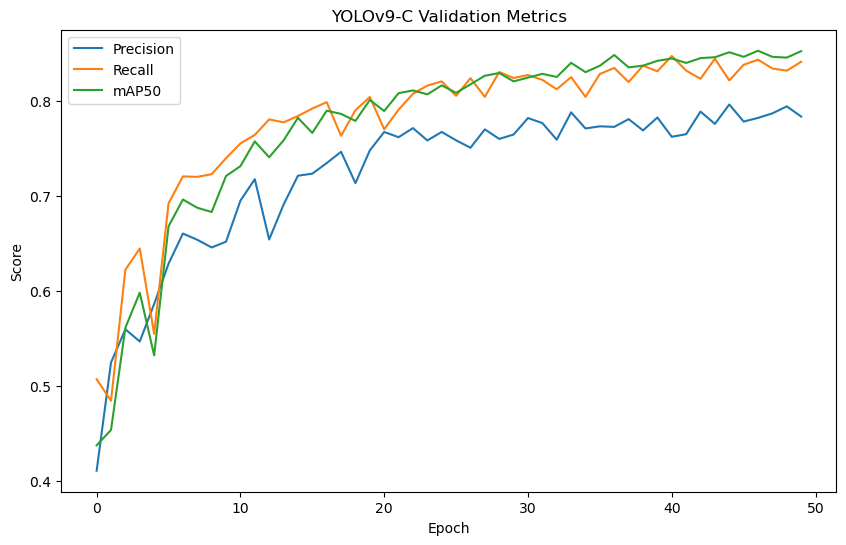

In [25]:
fig, ax = plt.subplots(figsize=(10,6))

ax.plot(
    yolov9_results["metrics/precision"],
    label="Precision"
)

ax.plot(
    yolov9_results["metrics/recall"],
    label="Recall"
)

ax.plot(
    yolov9_results["metrics/mAP_0.5"],
    label="mAP50"
)

ax.set_title("YOLOv9-C Validation Metrics")
ax.set_xlabel("Epoch")
ax.set_ylabel("Score")
ax.legend()

plt.show()

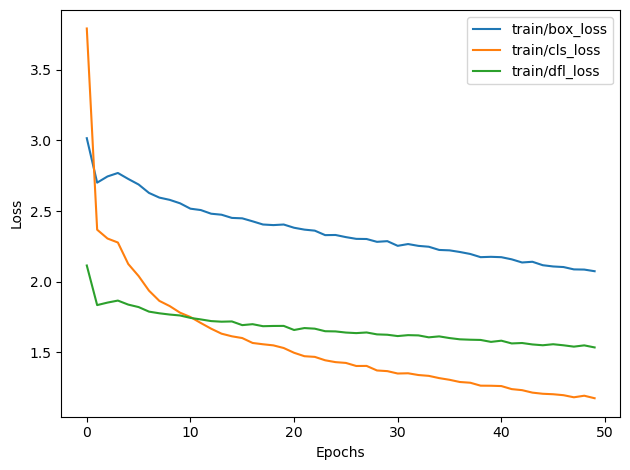

In [42]:
import matplotlib.pyplot as plt
%matplotlib inline


# BOX
plt.plot(yolov9_results["train/box_loss"])


# CLS
plt.plot(yolov9_results["train/cls_loss"])


# DFL
plt.plot(yolov9_results["train/dfl_loss"])

plt.legend(["train/box_loss", "train/cls_loss", "train/dfl_loss"])

plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.tight_layout()
plt.show()

In [35]:
yolov9_results.head()

,epoch,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision,metrics/recall,metrics/mAP_0.5,metrics/mAP_0.5:0.95,val/box_loss,val/cls_loss,val/dfl_loss,x/lr0,x/lr1,x/lr2
0,0,3.0157,3.7925,2.1145,0.41067,0.50696,0.43736,0.18226,0,0,0,0.070022,0.003331,0.003331
1,1,2.7011,2.3679,1.8341,0.52454,0.48424,0.45355,0.17562,0,0,0,0.039890,0.006532,0.006532
2,2,2.7450,2.3054,1.8519,0.55945,0.62209,0.56120,0.22973,0,0,0,0.009626,0.009602,0.009602
3,3,2.7695,2.2772,1.8661,0.54663,0.64453,0.59798,0.24017,0,0,0,0.009406,0.009406,0.009406
4,4,2.7272,2.1251,1.8376,0.58609,0.55463,0.53212,0.21518,0,0,0,0.009406,0.009406,0.009406


In [36]:
yolov9_results.tail()

,epoch,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision,metrics/recall,metrics/mAP_0.5,metrics/mAP_0.5:0.95,val/box_loss,val/cls_loss,val/dfl_loss,x/lr0,x/lr1,x/lr2
45,45,2.1076,1.2030,1.5570,0.77803,0.83778,0.84615,0.42222,0,0,0,0.001288,0.001288,0.001288
46,46,2.1035,1.1962,1.5495,0.78189,0.84315,0.85257,0.42994,0,0,0,0.001090,0.001090,0.001090
47,47,2.0869,1.1814,1.5400,0.78667,0.83383,0.84610,0.42142,0,0,0,0.000892,0.000892,0.000892
48,48,2.0856,1.1925,1.5490,0.79403,0.83157,0.84534,0.42445,0,0,0,0.000694,0.000694,0.000694
49,49,2.0740,1.1747,1.5344,0.78330,0.84094,0.85213,0.42920,0,0,0,0.000496,0.000496,0.000496


In [38]:
!python /home/f15c/H/yolov9/val_dual.py --data //home/f15c/H/Plastic_Shampoo_Bottle_Dataset/data.yaml --weights /home/f15c/H/runs/yolov9/YOLOv9C_Plastic_Shampoo_Bottle7/weights/best.pt --img 640 --batch 4 --device 0

val_dual: data=//home/f15c/H/Plastic_Shampoo_Bottle_Dataset/data.yaml, weights=['/home/f15c/H/runs/yolov9/YOLOv9C_Plastic_Shampoo_Bottle7/weights/best.pt'], batch_size=4, imgsz=640, conf_thres=0.001, iou_thres=0.7, max_det=300, task=val, device=0, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=yolov9/runs/val, name=exp, exist_ok=False, half=False, dnn=False, min_items=0
YOLO 🚀 v0.1-104-g5b1ea9a Python-3.12.11 torch-2.8.0+cu129 CUDA:0 (NVIDIA GeForce RTX 2080 SUPER, 7783MiB)

Fusing layers... 
yolov9-c summary: 604 layers, 50719068 parameters, 0 gradients, 236.7 GFLOPs
val: Scanning /home/f15c/H/Plastic_Shampoo_Bottle_Dataset/valid/labels... 1582 i
val: New cache created: /home/f15c/H/Plastic_Shampoo_Bottle_Dataset/valid/labels.cache
                 Class     Images  Instances          P          R      mAP50   Exception in thread Thread-6 (plot_images):
Traceback (most recent call last):
  File "/

In [39]:
YOLOV9_PRECISION = 0.782
YOLOV9_RECALL = 0.844
YOLOV9_MAP50 = 0.852
YOLOV9_MAP5095 = 0.430

YOLOV9_F1 = (
    2 * YOLOV9_PRECISION * YOLOV9_RECALL
) / (
    YOLOV9_PRECISION + YOLOV9_RECALL
)
 
print("Precision :", round(YOLOV9_PRECISION, 4))
print("Recall    :", round(YOLOV9_RECALL, 4))
print("F1 Score  :", round(YOLOV9_F1, 4))
print("mAP50     :", round(YOLOV9_MAP50, 4))
print("mAP50-95  :", round(YOLOV9_MAP5095, 4))

Precision : 0.782
Recall    : 0.844
F1 Score  : 0.8118
mAP50     : 0.852
mAP50-95  : 0.43
